In [1]:
import sys
from pathlib import Path
import pickle

import cv2 as cv
import numpy as np
import open3d as o3d

ROOT_DIR = next(
    directory
    for directory in (Path.cwd(), *Path.cwd().parents)
    if (directory / "src").is_dir() and (directory / "data").is_dir()
)
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))
CALIBRATION_DIR = ROOT_DIR / "data/calibration_results"
PROCESSED_DIR = ROOT_DIR / "data/processed"
REPORT_IMAGES_DIR = ROOT_DIR / "report/report_images"

from src.reconstruction import (
    create_stereo_matcher,
    compute_disparities,
    merge_global_point_cloud,
    build_local_point_cloud,
    create_charuco_detector,
    estimate_global_pose,
)
from src.calibration_rectification import rectify_image_pair
from src.utils.utils import indexed_images, get_image_at_index
from src.utils.prints import print_matrix
from src.utils.plotting import (
    show_disparity,
    show_geometries,
    save_open3d_screenshot,
)

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


# 1. Stereo Matching

In [2]:
# Mapas exportados por el notebook 01.
dataset_name = "palacio"
dataset_dir = ROOT_DIR / "data/raw" / dataset_name
dataset_output_dir = PROCESSED_DIR / dataset_name
disparity_dir = dataset_output_dir / "disparity"
disparity_dir.mkdir(parents=True, exist_ok=True)

with (CALIBRATION_DIR / "stereo_maps.pkl").open("rb") as stream:
    maps = pickle.load(stream)
left_rectification_map_x = np.asarray(maps["left_map_x"])
left_rectification_map_y = np.asarray(maps["left_map_y"])
right_rectification_map_x = np.asarray(maps["right_map_x"])
right_rectification_map_y = np.asarray(maps["right_map_y"])

In [3]:
left_by_index = indexed_images(dataset_dir, "left")
right_by_index = indexed_images(dataset_dir, "right")
pair_ids = sorted(left_by_index)
images_left = [str(left_by_index[index]) for index in pair_ids]
images_right = [str(right_by_index[index]) for index in pair_ids]

[OK] disp_0: 52.6% de píxeles válidos (WLS=sí)
[OK] disp_1: 52.7% de píxeles válidos (WLS=sí)
[OK] disp_2: 55.2% de píxeles válidos (WLS=sí)
[OK] disp_3: 57.4% de píxeles válidos (WLS=sí)
[OK] disp_4: 58.7% de píxeles válidos (WLS=sí)
[OK] disp_5: 57.8% de píxeles válidos (WLS=sí)
[OK] disp_6: 55.0% de píxeles válidos (WLS=sí)
[OK] disp_7: 55.7% de píxeles válidos (WLS=sí)
[OK] disp_8: 58.4% de píxeles válidos (WLS=sí)
[OK] disp_9: 56.0% de píxeles válidos (WLS=sí)
[OK] disp_10: 54.5% de píxeles válidos (WLS=sí)
[OK] disp_11: 55.8% de píxeles válidos (WLS=sí)
[OK] disp_12: 58.3% de píxeles válidos (WLS=sí)
[OK] disp_13: 56.8% de píxeles válidos (WLS=sí)
[OK] disp_14: 54.6% de píxeles válidos (WLS=sí)
[OK] disp_15: 52.0% de píxeles válidos (WLS=sí)
[OK] disp_16: 51.5% de píxeles válidos (WLS=sí)
[OK] disp_17: 56.0% de píxeles válidos (WLS=sí)
[OK] disp_18: 46.8% de píxeles válidos (WLS=sí)
[OK] disp_19: 44.5% de píxeles válidos (WLS=sí)
[OK] disp_20: 48.0% de píxeles válidos (WLS=sí)
[O

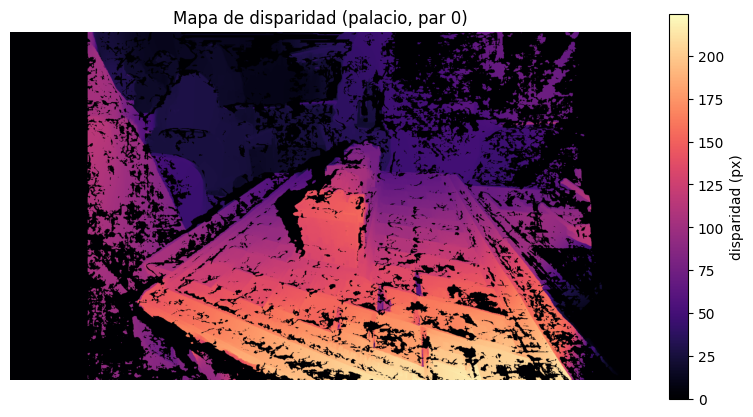

In [4]:
block_size = 11
min_disparity, num_disparities = 0, 240
stereo = create_stereo_matcher(
    min_disparity=min_disparity,
    num_disparities=num_disparities,
    block_size=block_size,
)
compute_disparities(
    images_left,
    images_right,
    stereo,
    left_rectification_map_x,
    left_rectification_map_y,
    right_rectification_map_x,
    right_rectification_map_y,
    str(disparity_dir),
    use_wls=True,
    lr_max_diff=1.5,
    min_confidence=0.0,
)
print(
    f"Disparidades guardadas en {disparity_dir.relative_to(PROCESSED_DIR)} ({len(pair_ids)} pares)"
)

disparity_example = np.load(disparity_dir / "disp_0.npy")
show_disparity(
    disparity_example,
    title=f"Mapa de disparidad ({dataset_name}, par 0)",
    save_path=REPORT_IMAGES_DIR / f"disparidad_{dataset_name}.png",
)

# 2. Computar Nube local

In [5]:
Q = np.asarray(maps["Q"])
Z_MIN, Z_MAX = 100.0, 2000.0

disparity_0 = np.load(disparity_dir / "disp_0.npy")
point_cloud_0 = build_local_point_cloud(
    str(left_by_index[0]),
    disparity_0,
    Q,
    left_rectification_map_x,
    left_rectification_map_y,
    min_disparity=min_disparity,
    z_min=Z_MIN,
    z_max=Z_MAX,
)
print(f"Nube local del par 0: {len(point_cloud_0.points):,} puntos")
show_geometries([point_cloud_0], title=f"Nube local - par 0 ({dataset_name})")

Nube local del par 0: 992,160 puntos


# 3. Pose global

In [6]:
rectified_intrinsic = np.asarray(maps["P1"])[:3, :3]
charuco_board, charuco_detector = create_charuco_detector()

img_left, img_right = get_image_at_index(dataset_name=dataset_name, index=0)
rect_left, _ = rectify_image_pair(img_left, img_right, maps)
camera_to_world_transform_0 = estimate_global_pose(
    cv.cvtColor(rect_left, cv.COLOR_BGR2GRAY),
    charuco_detector,
    charuco_board,
    rectified_intrinsic,
)
if camera_to_world_transform_0 is None:
    print("No se detectó el tablero en el par 0.")
else:
    print_matrix(
        "Pose del par 0 (cámara rectificada → mundo)", camera_to_world_transform_0
    )
    print(
        f"Posición de la cámara en el mundo: {np.round(camera_to_world_transform_0[:3, 3], 1)} mm"
    )

0.911777,0.114274,-0.394468,244.904
-0.405753,0.399091,-0.822248,691.733
0.0634665,0.909762,0.410249,-222.617
0,0,0,1


Posición de la cámara en el mundo: [ 244.9  691.7 -222.6] mm


# 4. Transformación

In [ ]:
global_point_cloud, camera_frames, merged_pair_count, discarded_pair_count = (
    merge_global_point_cloud(
        images_left,
        str(disparity_dir),
        Q,
        left_rectification_map_x,
        left_rectification_map_y,
        charuco_detector,
        charuco_board,
        rectified_intrinsic,
        min_disparity=min_disparity,
        z_min=Z_MIN,
        z_max=Z_MAX,
        voxel_size=2.0,  # Tamaño del vóxel en mm
        merge_every=1,   # Reducir la nube global en cada iteración
        # ROI desactivada por ahora
        roi_min=None,
        roi_max=None,
    )
)

print(
    f"Pares fusionados: {merged_pair_count} | "
    f"descartados sin tablero: {discarded_pair_count}"
)
print(f"Puntos en la nube global: {len(global_point_cloud.points):,}")

global_point_cloud_path = dataset_output_dir / f"nube_global_{dataset_name}.ply"
if not o3d.io.write_point_cloud(
    str(global_point_cloud_path), global_point_cloud
):
    raise OSError(f"No se pudo guardar {global_point_cloud_path}")

print("Nube global guardada en", global_point_cloud_path)

world_origin = o3d.geometry.TriangleMesh.create_coordinate_frame(size=100)
scene_geometries = [global_point_cloud, world_origin, *camera_frames]

save_open3d_screenshot(
    scene_geometries, str(REPORT_IMAGES_DIR / f"poses_{dataset_name}.png")
)
show_geometries(
    scene_geometries,
    title=f"Nube global en el marco de mundo ({dataset_name})",
)


[1] disp_0: 346,768 puntos locales; 346,768 puntos globales
[2] disp_1: 332,763 puntos locales; 599,765 puntos globales
[3] disp_2: 310,929 puntos locales; 827,414 puntos globales
[4] disp_3: 319,873 puntos locales; 1,056,583 puntos globales
[5] disp_5: 323,377 puntos locales; 1,291,365 puntos globales
[6] disp_6: 318,327 puntos locales; 1,541,394 puntos globales
[7] disp_7: 359,456 puntos locales; 1,826,921 puntos globales
[8] disp_9: 349,317 puntos locales; 2,104,030 puntos globales
[9] disp_10: 357,649 puntos locales; 2,379,813 puntos globales
[10] disp_11: 338,715 puntos locales; 2,633,199 puntos globales
[11] disp_12: 363,148 puntos locales; 2,888,726 puntos globales
[12] disp_13: 343,536 puntos locales; 3,144,141 puntos globales
[13] disp_14: 353,204 puntos locales; 3,290,142 puntos globales
[14] disp_15: 384,753 puntos locales; 3,579,684 puntos globales
[15] disp_16: 341,706 puntos locales; 3,815,899 puntos globales
[16] disp_17: 316,173 puntos locales; 4,038,861 puntos globales

: 